### Top

In [1]:
from volta.prelude import *

In [2]:
meshcat = StartMeshcat()
#  http://tanawat@carver-System-Product-Name.local:<your_port>

INFO:drake:Meshcat listening for connections at http://localhost:7001


### Simulation parameters

In [3]:
# Robot leg's diamention
L1 = 0.054
L2 = 0.03
L3 = 0.1605
L4 = 0.166
L5 = 0.049
link_lengths = [L1,L2,L3,L4,L5]
sim_time_step = 0.0001    # [second]

In [4]:
# Controller configulation
gravity_compensation_enable = False
cotroller_enable = True
controller = "mit"  # mit or cascade

# Simularion configulation
fixed_base = False
gravity_enable = True 
realtime = False
save_graph = False
gravity = [0, 0, -9.81*gravity_enable]

# Robot initial pose configulation
body_high = 0.265
# body_high = 0.4055 # high when all q are 0
hip_high  = body_high
init_pos = [0.0 ,0.002, body_high+(0.15*fixed_base)] # body frame position [m] from world frame
init_orien = np.asarray([0, 0, 0]) # body fram orientation [degree] rotate xyz fixed axis
step_forward = 4  
sample_name = 'step10cmV4_2'

### Load joint position

/home/tanawatp/Documents/Thesis_simulation/Simulation

In [5]:
# Load the variables back
loaded_data = np.load(f"/home/tanawatp/Documents/Thesis_simulation/Simulation/q_data/q_data_{sample_name}.npz")
q_L = loaded_data['arr_0'].T
q_R = loaded_data['arr_1'].T
T = loaded_data['arr_4'][0] 
q_R[:,-1] = q_R[:,-1] + (q_R[:,-1] - q_L[:,0])*0.5
q_L[:,-1] = q_L[:,-1] + (q_L[:,-1] - q_R[:,0])*0.5
loaded_qd_data = np.load(f"/home/tanawatp/Documents/Thesis_simulation/Simulation/q_data/qd_data_{sample_name}.npz")
qd_L = loaded_qd_data['arr_0'].T
qd_R = loaded_qd_data['arr_1'].T
loaded_q_init_data = np.load(f"/home/tanawatp/Documents/Thesis_simulation/Simulation/q_data/q_init_data_{sample_name}.npz")
q_L_init = loaded_q_init_data['arr_0']
q_R_init = loaded_q_init_data['arr_1']
loaded_full_CoM_data = np.load("/home/tanawatp/Documents/Thesis_simulation/Simulation/FinalProgress/Datas/CoMDatas/full_com_data_step10cmV4_2.npz")
CoM_x = loaded_full_CoM_data['arr_0']
CoM_y = loaded_full_CoM_data['arr_1']
CoM_z = loaded_full_CoM_data['arr_2']
foot_placement_position = loaded_full_CoM_data['arr_3']
sole_size = loaded_full_CoM_data['arr_4']

In [6]:
print(T)
sim_time = step_forward*T + 5
print(sim_time)

5.63
27.52


In [7]:
body_R_Lfoot = np.array([
                        [0,-1, 0],
                        [0, 0, 1],
                        [-1,0, 0],
                        [0, 0, 0]])
# body_P_Lfoot = np.array([[-0.049, 0.0, -hip_high, 1]]).T
body_P_Lfoot = np.array([[-0.09175898, 0.20999674, -0.26252952, 1]]).T
body_T_Lfoot = np.concatenate((body_R_Lfoot,body_P_Lfoot),axis=1)
T_left_flatten = body_T_Lfoot.flatten() 
body_R_Rfoot = np.array([
                        [0,-1, 0],
                        [0, 0, 1],
                        [-1,0, 0],
                        [0, 0, 0]])
body_P_Rfoot = np.array([[0.049, -0.0, -hip_high, 1]]).T
body_T_Rfoot = np.concatenate((body_R_Rfoot,body_P_Rfoot),axis=1)
T_right_flatten = body_T_Rfoot.flatten() 


### Create multibody plant and diagram

In [8]:
meshcat.Delete()
meshcat.DeleteAddedControls()
DisplayPointTrajectory(meshcat=meshcat,
                    trajectory_x=CoM_x,
                    trajectory_y=CoM_y,
                    trajectory_z=CoM_z)
DisplayFootPlacementArea(meshcat=meshcat,
                         foot_placement_position=foot_placement_position,
                         foot_size=sole_size)
dir = "/home/tanawatp/Documents/Thesis_simulation/Models"
robot_urdf = "humanoid_half_body.urdf"
robot_urdf_path = os.path.join(dir,robot_urdf)
floor_sdf = "floor_top.sdf"
floor_sdf_path = os.path.join(dir,floor_sdf)

builder = DiagramBuilder()
plant, scene_graph = AddMultibodyPlantSceneGraph(
    builder, time_step=sim_time_step)
parser = Parser(plant)

# Set the gravity feild
plant.mutable_gravity_field().set_gravity_vector(gravity)

# Add models to multibody plant
robot_instant_index = parser.AddModels(robot_urdf_path)
floor = parser.AddModels(floor_sdf_path)

# Weld the floor to the world so that it's fixed during the simulation.
floor_frame = plant.GetFrameByName("floor_top_center")
temp0 = RigidTransform(
    RollPitchYaw([0,0,0]), p=[0.0,0,0])
plant.WeldFrames(plant.world_frame(), floor_frame,temp0)

X_floorRobot = RigidTransform(
    RollPitchYaw(init_orien * np.pi / 180), p=init_pos)
if fixed_base:
    robot_body_frame = plant.GetFrameByName("torso")
    plant.WeldFrames(plant.world_frame(),robot_body_frame, X_floorRobot)
    print("Simulation in Fixed based mode")
else:
    print("Simulation in Folating based mode")

plant.Finalize()

# Set initial pose of robot
plant_context = plant.CreateDefaultContext()
robot = plant.GetBodyByName("torso")
X_Worldfloor = floor_frame.CalcPoseInWorld(plant_context) 

X_WorldRobot = X_Worldfloor.multiply(X_floorRobot)
plant.SetDefaultFreeBodyPose(robot, X_WorldRobot)


Simulation in Folating based mode


### Add and connect system 

In [9]:
if controller == "mit":
    num_actuators = plant.num_actuated_dofs()
    # kp =  [4.0, 12.0,  12.0,  12.0, 12.0, 9.0]
    # kd = [0.06, 0.04, 0.04, 0.04, 0.06, 0.2]
    kp =  [6.0, 25.0,  20.0,  14.0, 20.0, 15.0]
    kd = [0.06, 0.15, 0.08, 0.06, 0.06, 0.15]


    MIT_controller = builder.AddNamedSystem("MIT controller",
                                            MITController(kp=kp + kp,
                                                        kd=kd + kd,
                                                        dt=0.01))
    if gravity_compensation_enable:
        gravity_compensation = builder.AddNamedSystem("Gravity compensation",
                                                GravityCompensation(dt=0.01))
        torque_summation = builder.AddNamedSystem("Torque summation",
                                            Sum(port_shape=12))
        contact_force_sensor = builder.AddNamedSystem("Contact force sensor",
                                            ContactForceSensor(dt=0.01,plant=plant))

    # CoM 
    walk_recorder = builder.AddNamedSystem("Walk recorder",
                                        WalkRecorder(plant=plant,context=plant_context,model_instances=robot_instant_index))

    # State feedback
    robot_state_recorder = builder.AddNamedSystem("Robot states recorder",
                                                JointStateRecorder(plant=plant))



    # Dummy param
    dummy_param = builder.AddNamedSystem("Dummy parameters",
                                        DummyParameters(loaded_q_init_data, q_L, q_R, qd_L, qd_R))





TypeError: WalkRecorder.__init__() missing 1 required positional argument: 'meshcat'

In [ ]:
if controller == "cascade":
    num_actuators = plant.num_actuated_dofs()

    kp_qd = [0.01,   0.05,  0.02,   0.03,    0.02,  0.02]
    ki_qd = [0.0,   0.00,  0.0,   0.0,    0.0,  0.01]
    kd_qd = [0.000, 0.0003, 0.000, 0.0001, 0.000, 0.00001]
    velocity_controller = builder.AddNamedSystem("velocity controller",
                                                PidController(kp= kp_qd + kp_qd, 
                                                            ki= ki_qd + ki_qd, 
                                                            kd= kd_qd + kd_qd))
    # Demux
    demux_qd_feedback = builder.AddNamedSystem("demux qd feedback",
                                                DeMux2(input_size=24))
    demux_qd_reference = builder.AddNamedSystem("demux qd reference",
                                                DeMux2(input_size=24))
    # Rate transition
    rate_transition = builder.AddNamedSystem("rate transition",
                                                RateTransition(dt= 0.01))
    
    kp_q = [850.0,   850.0,  850.0,   850.0,    850.0,  850.0]
    ki_q = [0.0,   0.0,  0.0,   00.0,    0.0,  0.0]
    kd_q = [0.0002,   0.0002,  0.0002,   0.0002,    0.0002,  0.0002]
    position_controller = builder.AddNamedSystem("position controller",
                                                PidController(kp= kp_q + kp_q, 
                                                            ki= ki_q + ki_q, 
                                                            kd= kd_q + kd_q))
    if gravity_compensation_enable:
        gravity_compensation = builder.AddNamedSystem("Gravity compensation",
                                                GravityCompensation(dt=0.01))
        torque_summation = builder.AddNamedSystem("Torque summation",
                                            Sum(port_shape=12))
        contact_force_sensor = builder.AddNamedSystem("Contact force sensor",
                                            ContactForceSensor(dt=0.01,plant=plant))

    # CoM 
    walk_recorder = builder.AddNamedSystem("Walk_recorder",
                                        WalkRecorder(plant=plant,context=plant_context,model_instances=robot_instant_index))

    # State feedback
    robot_state_recorder = builder.AddNamedSystem("Robot_state_recorder",
                                                JointStateRecorder(plant=plant))
    # builder.Connect(
    #     robot_state_recorder.get_output_port(2), # joint position
    #     controller.get_input_port(4))
            
    # Dummy param
    dummy_param = builder.AddNamedSystem("Dummy parameters",
                                        DummyParameters(loaded_q_init_data, q_L, q_R, qd_L, qd_R))

### Wire the systems

In [ ]:
if controller == "mit":
    builder.Connect(
        dummy_param.get_output_port(4),
        MIT_controller.get_input_port(0))
    
    builder.Connect(
        robot_state_recorder.get_output_port(4),
        MIT_controller.get_input_port(1))


    
    if gravity_compensation_enable and cotroller_enable:
        builder.Connect(
            gravity_compensation.get_output_port(0),
            torque_summation.get_input_port(0))
        
        builder.Connect(
            MIT_controller.get_output_port(0),
            torque_summation.get_input_port(1))
        
        builder.Connect(
                plant.get_state_output_port(robot_instant_index[0]),
                gravity_compensation.get_input_port(0))
        
        builder.Connect(
                contact_force_sensor.get_output_port(0),
                gravity_compensation.get_input_port(1))
        
        builder.Connect(
            torque_summation.get_output_port(0),
            plant.get_actuation_input_port(robot_instant_index[0]))
        builder.Connect(
            plant.get_contact_results_output_port(),
            contact_force_sensor.get_input_port(0))
        
    elif gravity_compensation_enable == False and cotroller_enable:
        builder.Connect(
            MIT_controller.get_output_port(0),
            plant.get_actuation_input_port(robot_instant_index[0]))
    
    # Connect to plant's output 
    builder.Connect(
        plant.get_state_output_port(robot_instant_index[0]), # robot states
        robot_state_recorder.get_input_port(0))

In [ ]:
if controller == "cascade":   
    # Demux
    builder.Connect(
        robot_state_recorder.get_output_port(4), # [q,qd] feedback
        demux_qd_feedback.get_input_port(0))
    builder.Connect(
        dummy_param.get_output_port(4), # [q,qd] reference
        demux_qd_reference.get_input_port(0))
        
    # Rate transition input
    builder.Connect(
        demux_qd_reference.get_output_port(1), # qd_reference
        rate_transition.get_input_port(0))
    builder.Connect(
        position_controller.get_output_port_control(), # qd_u
        rate_transition.get_input_port(1))
    builder.Connect(
        demux_qd_feedback.get_output_port(1), # qd_feedback
        rate_transition.get_input_port(2))

    # Position controller input
    builder.Connect(
        robot_state_recorder.get_output_port(4), # [q,qd] feedback
        position_controller.get_input_port_estimated_state())
    builder.Connect(
        dummy_param.get_output_port(4), # [q,qd] reference
        position_controller.get_input_port_desired_state())
    
    if gravity_compensation_enable and cotroller_enable:
        builder.Connect(
            gravity_compensation.get_output_port(0),
            torque_summation.get_input_port(0))
        
        builder.Connect(
            velocity_controller.get_output_port_control(),
            torque_summation.get_input_port(1))
        
        builder.Connect(
                plant.get_state_output_port(robot_instant_index[0]),
                gravity_compensation.get_input_port(0))
        
        builder.Connect(
                contact_force_sensor.get_output_port(0),
                gravity_compensation.get_input_port(1))
        
        builder.Connect(
            torque_summation.get_output_port(0),
            plant.get_actuation_input_port(robot_instant_index[0]))
        builder.Connect(
            plant.get_contact_results_output_port(),
            contact_force_sensor.get_input_port(0))
    elif gravity_compensation_enable == False and cotroller_enable:
        builder.Connect(
            velocity_controller.get_output_port_control(),
            plant.get_actuation_input_port(robot_instant_index[0]))

    # Velocity controller input
    builder.Connect(
        rate_transition.get_output_port(0), # [qd,qdd] estimate
        velocity_controller.get_input_port_estimated_state())
    builder.Connect(
        rate_transition.get_output_port(1), # [qd,qdd] reference
        velocity_controller.get_input_port_desired_state())

    # Connect to plant's output 
    builder.Connect(
        plant.get_state_output_port(robot_instant_index[0]), # robot states
        robot_state_recorder.get_input_port(0))


### Loggers

In [ ]:
if controller == "mit":
    [body_pos_logger, body_vel_logger, q_logger, qd_logger] = CreateLoggers(builder=builder, 
                                                                            system=robot_state_recorder, 
                                                                            port_num=[0,1,2,3], 
                                                                            name = ["body_pos_logger", "body_vel_logger","q_logger", "qd_logger"])

    [sw_q_logger, st_q_logger, sw_qd_logger, st_qd_logger, leg_state_logger] = CreateLoggers(builder=builder, 
                                                                        system=dummy_param, 
                                                                        port_num=[0,1,2,3,4], 
                                                                        name = ["sw_q_logger", "st_q_logger", "sw_qd_logger", "st_qd_logger","leg_state_logger"])

    [com_W_logger, com_base_logger, W_P_torso_logger,L_P_com_logger,R_P_com_logger] = CreateLoggers(builder=builder,
                                                    system=walk_recorder, 
                                                    port_num=[0,1,2,3,4], 
                                                    name = ["com_W_logger", "com_base_logger", "W_P_torso_logger","L_P_com_logger", "R_P_com_logger"])
    if gravity_compensation_enable:
        [torque_command_logger] = CreateLoggers(builder=builder,
                                            system= torque_summation,
                                            port_num=[0],
                                            name=["torque_command_logger"])
    else:
        [torque_command_logger] = CreateLoggers(builder=builder,
                                            system= MIT_controller,
                                            port_num=[0],
                                            name=["torque_command_logger"])

In [ ]:
if controller == "cascade":
    [body_pos_logger, body_vel_logger, q_logger, qd_logger] = CreateLoggers(builder=builder, 
                                                                            system=robot_state_recorder, 
                                                                            port_num=[0,1,2,3], 
                                                                            name = ["body_pos_logger", "body_vel_logger","q_logger", "qd_logger"])
    if gravity_compensation_enable:
        [torque_command_logger] = CreateLoggers(builder=builder,
                                            system= torque_summation,
                                            port_num=[0],
                                            name=["torque_command_logger"])
    else:
        torque_command_logger = LogVectorOutput(velocity_controller.get_output_port_control(), builder)
    [qd_estimate_logger, qd_desire_logger] = CreateLoggers(builder=builder,system=rate_transition,
                                            port_num=[0,1],
                                            name=["qd_estimate", "qd_desire"])

    [sw_q_logger, st_q_logger, sw_qd_logger, st_qd_logger, leg_state_logger] = CreateLoggers(builder=builder, 
                                                                        system=dummy_param, 
                                                                        port_num=[0,1,2,3,4], 
                                                                        name = ["sw_q_logger", "st_q_logger", "sw_qd_logger", "st_qd_logger","leg_state_logger"])

    [com_W_logger, com_base_logger, W_P_torso_logger] = CreateLoggers(builder=builder, 
                                                    system=walk_recorder, 
                                                    port_num=[0,1,2], 
                                                    name = ["com_W_logger", "com_base_logger", "W_P_torso_logger"])

## Add visualization

In [ ]:
AddDefaultVisualization(builder=builder, meshcat=meshcat)
diagram = builder.Build()
diagram.set_name("Robot simulation")

## Show the diagram

In [ ]:
import pydot

Note: you may need to restart the kernel to use updated packages.


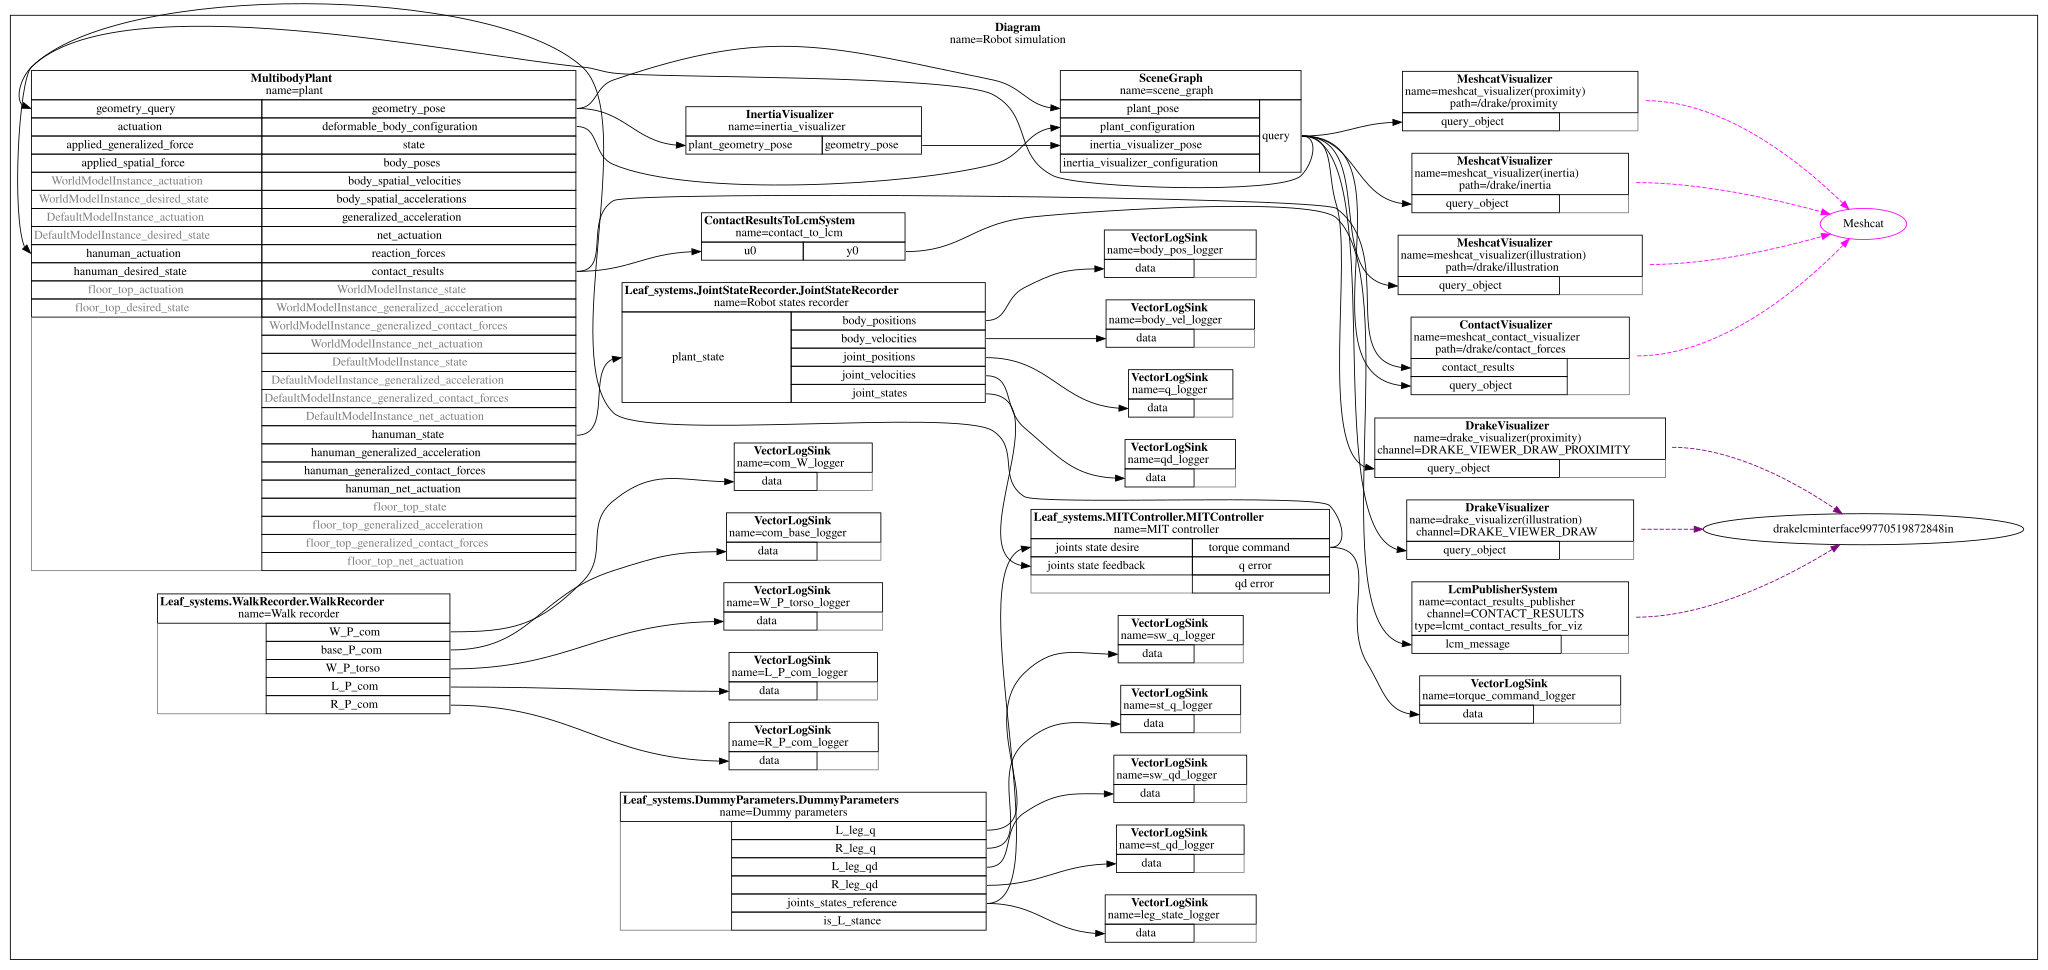

In [ ]:
# Install the Python graphviz package
%pip install graphviz

# Install the Graphviz system package (for Ubuntu/Debian)
# Remove the comment below and run this cell if you still get the "dot not found" error.
# You may need to restart the kernel after installing.
# !apt-get update && apt-get install -y graphviz

# Now you can safely call your function
show_diagram(diagram=diagram, show=True)

# Exicute simulation

In [ ]:
ind = 0
left_q = q_L_init[:,ind]
right_q = q_R_init[:,ind]
left_qd = np.zeros(6)
right_qd = np.zeros(6)

In [ ]:
simulator = Simulator(diagram)
new_context = diagram.CreateDefaultContext()
simulator.reset_context(new_context)
context = simulator.get_mutable_context()

# controller.system_context = context
dummy_param.ind = 0
plant_context = plant.GetMyContextFromRoot(context)
walk_recorder.root_context = context
num_positions = plant.num_positions(robot_instant_index[0])  # Get the total number of positions in the plant

body_quanternion_xyzw = np.array([R.from_euler('xyz', init_orien*np.pi/180.0).as_quat()])[0]


body_quanternion_wxyz = [body_quanternion_xyzw[3], body_quanternion_xyzw[0], body_quanternion_xyzw[1], body_quanternion_xyzw[2]]
body_pose = np.concatenate((np.array([body_quanternion_wxyz]), np.array([init_pos])), axis=1)


initial_joint_positions = np.concatenate((np.array([left_q]), np.array([right_q])), axis=1)
initial_joint_velocities = np.concatenate((np.array([left_qd]), np.array([right_qd])), axis=1)
if fixed_base:
    initial_q = initial_joint_positions[0] # fixed base
    initial_qd = initial_joint_velocities[0]
else:
    initial_q = np.concatenate((body_pose, initial_joint_positions),axis=1)[0] # floating base
    initial_qd = np.concatenate((np.zeros([1,6]), initial_joint_positions),axis=1)[0]

plant.SetPositions(plant_context, robot_instant_index[0], initial_q)
# plant.SetVelocities(plant_context, robot_instant_index[0], initial_qd)
simulator.Initialize()

if realtime:
    simulator.set_target_realtime_rate(1.0)
meshcat.StartRecording()
simulator.AdvanceTo(sim_time)
meshcat.PublishRecording()



==== LCM Warning ===
LCM detected that large packets are being received, but the kernel UDP
receive buffer is very small.  The possibility of dropping packets due to
insufficient buffer space is very high.

For more information, visit:
   https://lcm-proj.github.io/lcm/content/multicast-setup.html



sim R_P_com 0.0  :  [0.01043632 0.05402304 0.16689796]
sim L_P_com 0.0  :  [ 0.01043552 -0.05347835  0.16689795]
0.0  :  double_stance
sim R_P_com 0.01  :  [0.01019816 0.05398024 0.167484  ]
sim L_P_com 0.01  :  [ 0.01019535 -0.05343437  0.16748518]
0.01  :  double_stance
sim R_P_com 0.02  :  [0.00993198 0.05405115 0.16835182]
sim L_P_com 0.02  :  [ 0.0099196  -0.05350631  0.16835154]
0.02  :  double_stance
sim R_P_com 0.03  :  [0.00954661 0.05405461 0.16785297]
sim L_P_com 0.03  :  [ 0.00953428 -0.05349599  0.16785347]
0.03  :  double_stance
sim R_P_com 0.04  :  [0.00989259 0.05406111 0.16721126]
sim L_P_com 0.04  :  [ 0.00987969 -0.053491    0.16721169]
0.04  :  double_stance
sim R_P_com 0.05  :  [0.01019438 0.05406626 0.16674542]
sim L_P_com 0.05  :  [ 0.01018195 -0.05348237  0.16674499]
0.05  :  double_stance
sim R_P_com 0.06  :  [0.01043174 0.05407909 0.16645476]
sim L_P_com 0.06  :  [ 0.01042209 -0.05347163  0.16645576]
0.06  :  double_stance
sim R_P_com 0.07  :  [0.01061369 0.05

In [ ]:
print(f"{meshcat.web_url()}/download")

http://localhost:7000/download


In [ ]:
L_foot_contact_frame = plant.GetFrameByName("L_foot_contact")
W_T_Lsole = L_foot_contact_frame.CalcPoseInWorld(plant_context)
W_P_Lsole = W_T_Lsole.translation()
print(W_P_Lsole)
R_foot_contact_frame = plant.GetFrameByName("R_foot_contact")   
W_T_Rsole = R_foot_contact_frame.CalcPoseInWorld(plant_context)   
W_P_Rsole = W_T_Rsole.translation()  
print(W_P_Rsole)
torso_frame = plant.GetFrameByName("torso")   
W_T_torso = torso_frame.CalcPoseInWorld(plant_context)   
W_P_torso = W_T_torso.translation()  
print(W_P_torso)

[ 4.09273647e-01  5.04692888e-02 -2.71665638e-05]
[ 5.11280740e-01 -5.95930454e-02  3.83817954e-05]
[0.45503762 0.00973472 0.35101644]


In [ ]:
print("Controller            : ", controller)
print("Gravity compensation  : ", gravity_compensation_enable)
print("Torso final position  :", W_P_torso)
print("L foot final position :", W_P_Lsole)
print("R foot final position :", W_P_Rsole)

Controller            :  mit
Gravity compensation  :  True
Torso final position  : [0.45503762 0.00973472 0.35101644]
L foot final position : [ 4.09273647e-01  5.04692888e-02 -2.71665638e-05]
R foot final position : [ 5.11280740e-01 -5.95930454e-02  3.83817954e-05]


### Contact Result


In [ ]:
contact_results = plant.get_contact_results_output_port().Eval(plant_context)
GRF = 0
info = None
for i in range(contact_results.num_point_pair_contacts()):
    info = contact_results.point_pair_contact_info(i)

    bodyA_index = info.bodyA_index()
    bodyB_index = info.bodyB_index()

    # Look up body names from indices
    bodyA_name = plant.get_body(bodyA_index).name()
    bodyB_name = plant.get_body(bodyB_index).name()

    print(f"Contact between '{bodyA_name}' and '{bodyB_name}'")
    print(f"  Force in world frame: {info.contact_force()}")
    print(f"  Point in world frame: {info.contact_point()}")
    GRF += -info.contact_force()[2]
print("Ground Reaction Force: ", GRF)

Contact between 'L_foot' and 'floor_top_link'
  Force in world frame: [  8.53564986  -8.23923589 -14.15684839]
  Point in world frame: [ 5.04708366e-01  2.17622334e-02 -6.83379360e-06]
Contact between 'R_foot' and 'floor_top_link'
  Force in world frame: [14.4876087   0.72527325 -9.98135177]
  Point in world frame: [ 6.07408107e-01 -3.32021309e-02 -4.15958418e-06]
Ground Reaction Force:  24.138200164883923


# Plot

In [ ]:
L_log = sw_q_logger.FindLog(context)
R_log = st_q_logger.FindLog(context)
q_log = q_logger.FindLog(context)
leg_state_log = leg_state_logger.FindLog(context)
L_qd_log = sw_qd_logger.FindLog(context)
R_qd_log = st_qd_logger.FindLog(context)
qd_log = qd_logger.FindLog(context)
torque_command_log = torque_command_logger.FindLog(context)

torso_P_com_log = com_base_logger.FindLog(context) 
W_P_torso_log = W_P_torso_logger.FindLog(context)
W_P_com_log = com_W_logger.FindLog(context)
t = q_log.sample_times()
n = plant.num_positions()

dir = "/home/tanawat/Documents/Thesis/Thesis_simulation/Simulation/FinalProgress/Datas/JointDatas/SimulationResult/"


In [ ]:
np.savez(f"{dir}sim_{controller}_gcomp{gravity_compensation_enable}_q_data_{sample_name}",
         T,
         t, 
         q_log.data(),
         L_log.data(),
         R_log.data(),    
         )
np.savez(f"{dir}sim_{controller}_gcomp{gravity_compensation_enable}_qd_data_{sample_name}",
         T,
         t, 
         qd_log.data(),
         L_qd_log.data(),
         R_qd_log.data()       
         )

In [ ]:
np.savez(f"{dir}sim_{controller}_gcomp{gravity_compensation_enable}_torque_data_{sample_name}",
         t, 
         torque_command_log.data(),
         leg_state_log.data()    
         )

In [ ]:
np.savez(f"{dir}sim_{controller}_gcomp{gravity_compensation_enable}_CoM_data_{sample_name}",
         t, 
         W_P_com_log.data(),
         W_P_torso_log.data()   
         )

In [ ]:
np.savez(f"{dir}sim_{controller}_gcomp{gravity_compensation_enable}_final_position_data_{sample_name}",
         W_P_torso,
         W_P_Lsole,
         W_P_Rsole   
         )

In [ ]:
loaded_q_comp = np.load(f"/home/tanawat/Documents/Thesis/Thesis_simulation/Simulation/q_data/gravity_compensation/q_with_gravity_comp.npz")
q_comp = loaded_q_comp['arr_0']
# loaded_q_no_comp = np.load(f"/home/tanawat/Documents/Thesis/Thesis_simulation/Simulation/q_data/gravity_compensation/q_with_no_gravity_comp.npz")
# q_no_comp = loaded_q_no_comp['arr_0']

### q vs time

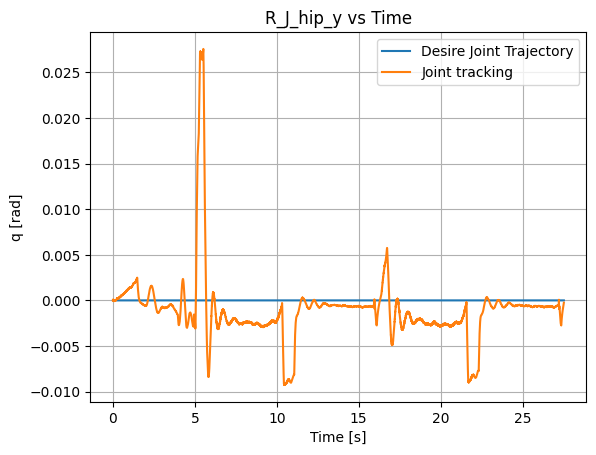

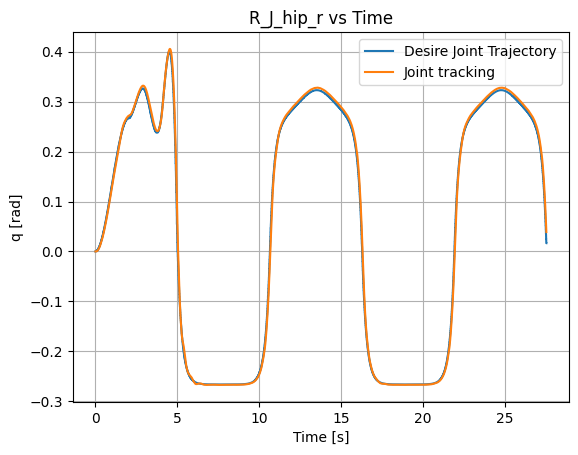

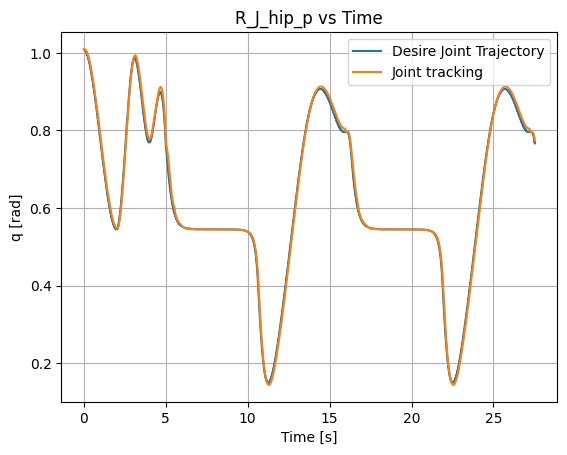

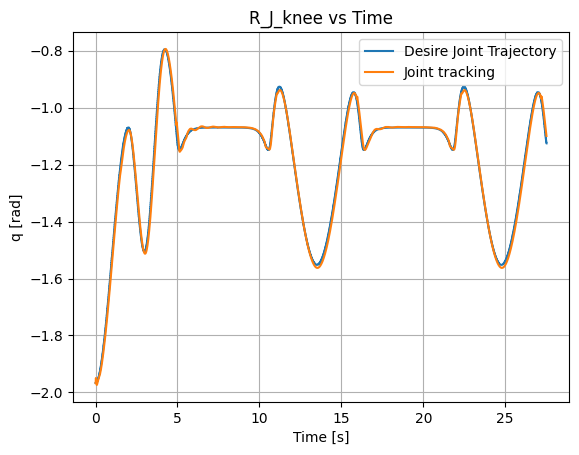

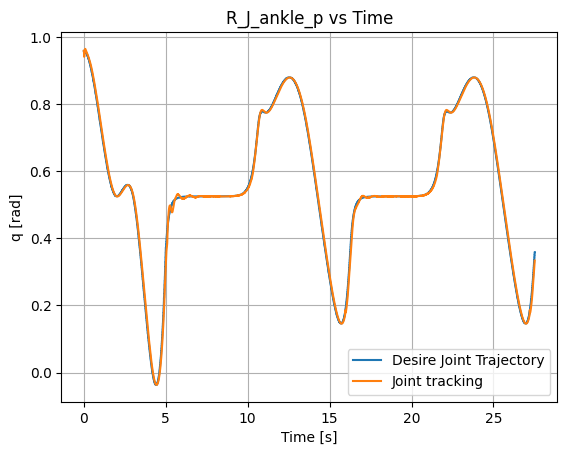

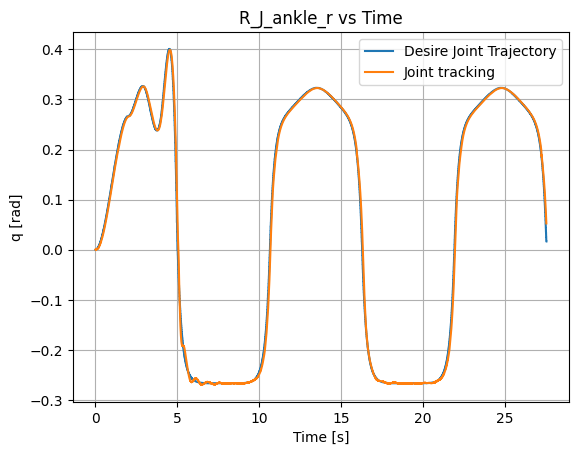

In [ ]:
# name = ["JL_hip_y","JL_hip_r","JL_hip_p","JL_knee","JL_ankle_p","JL_ankle_r"]
name = ["J_hip_y","J_hip_r","J_hip_p","J_knee","J_ankle_p","J_ankle_r"]
for i in range(6):
    temp = name[i]
    sw_label = f"R_reference_{temp}"
    q_label = f"R_actual_{temp}"
    temp2 = np.ones(q_log.sample_times().size) * initial_joint_positions[0,6+i]
    plt.plot(q_log.sample_times(),R_log.data()[i,:],label = f"Desire Joint Trajectory")
    plt.plot(q_log.sample_times(),q_log.data()[6+i,:],label = f"Joint tracking")

    plt.xlabel("Time [s]")
    plt.ylabel("q [rad]")
    plt.title(f"R_{temp} vs Time")
    plt.legend()
    plt.grid()


    plt.show()

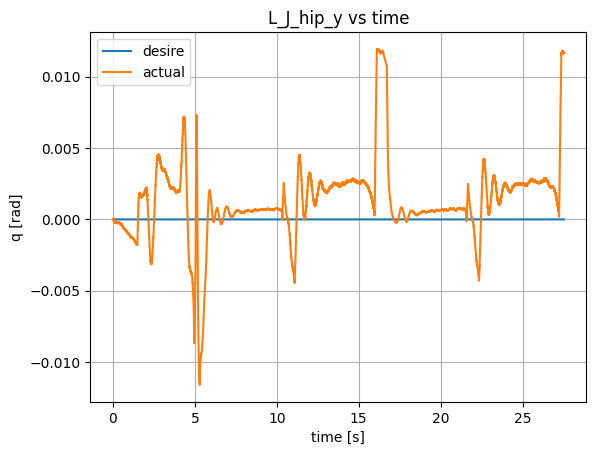

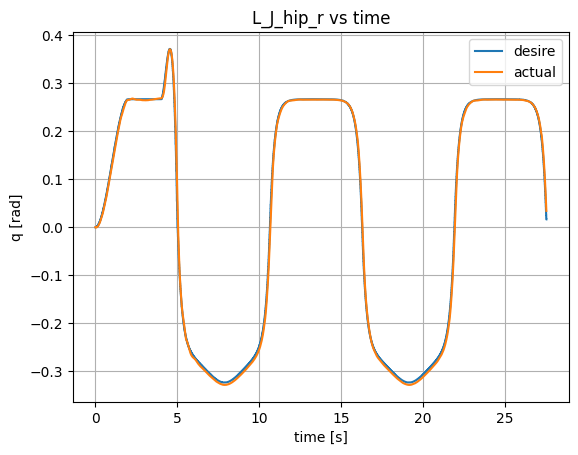

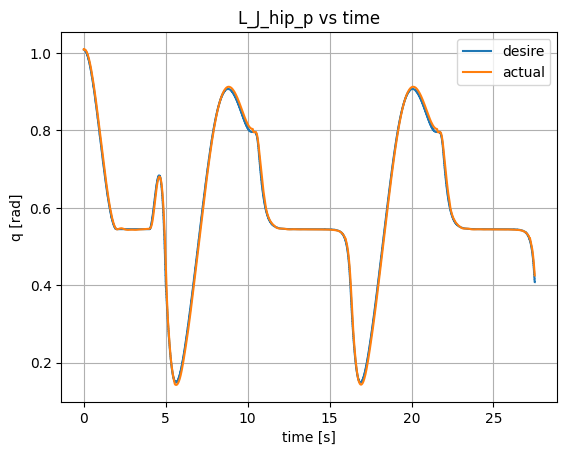

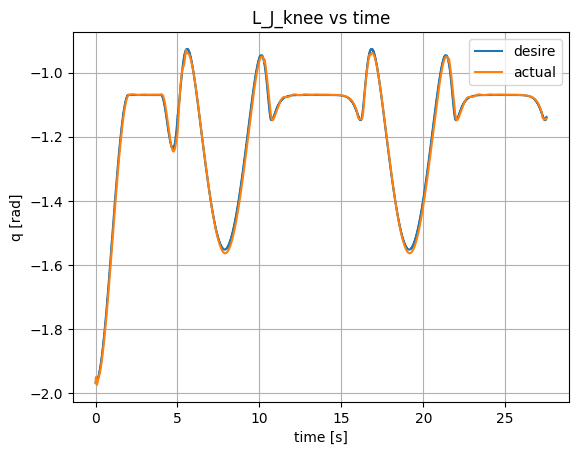

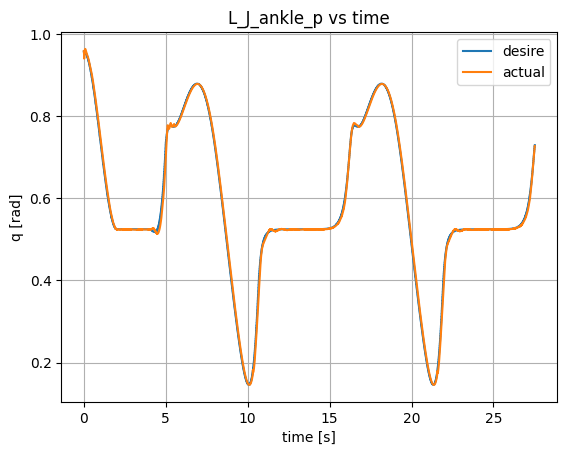

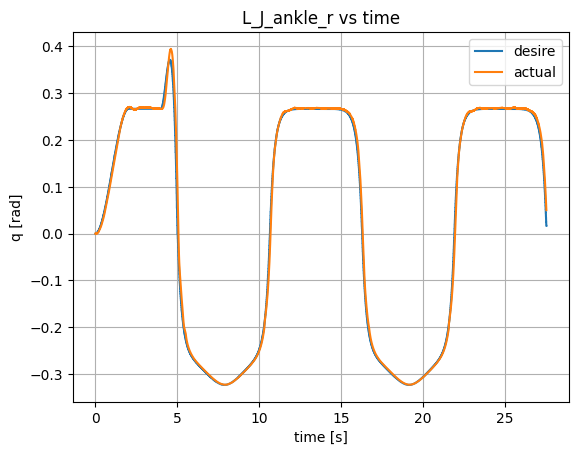

In [ ]:
for i in range(6):
    temp = name[i]
    sw_label = f"R_reference_{temp}"
    q_label = f"R_actual_{temp}"
    temp2 = np.ones(q_log.sample_times().size) * initial_joint_positions[0,6+i]
    plt.plot(q_log.sample_times(),L_log.data()[i,:],label = f"desire")  
    plt.plot(q_log.sample_times(),q_log.data()[i,:],label = f"actual")

    plt.xlabel("time [s]")
    plt.ylabel("q [rad]")
    plt.title(f"L_{temp} vs time")
    plt.legend()
    plt.grid()
    plt.show()

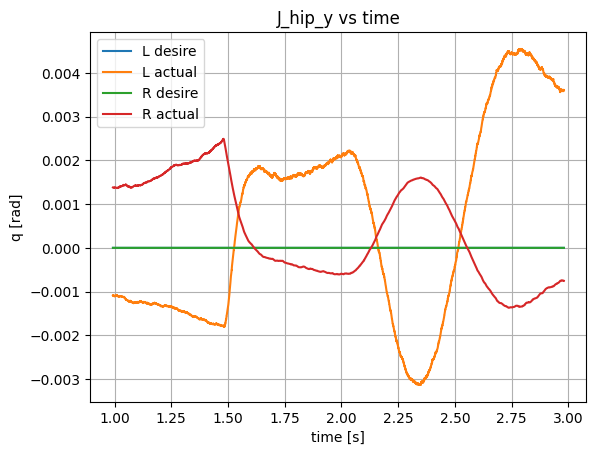

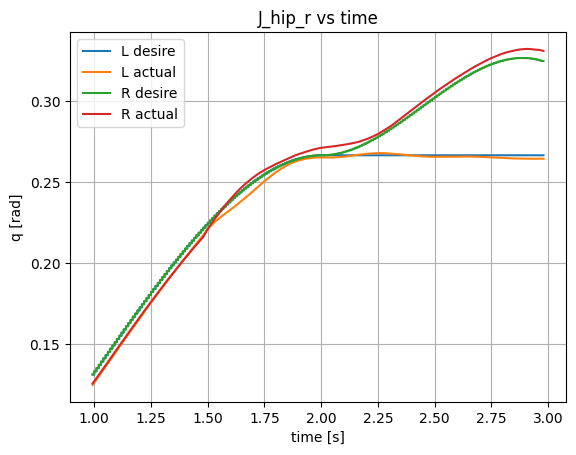

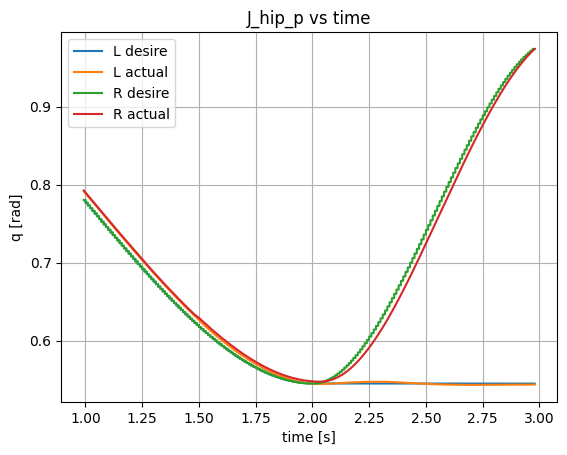

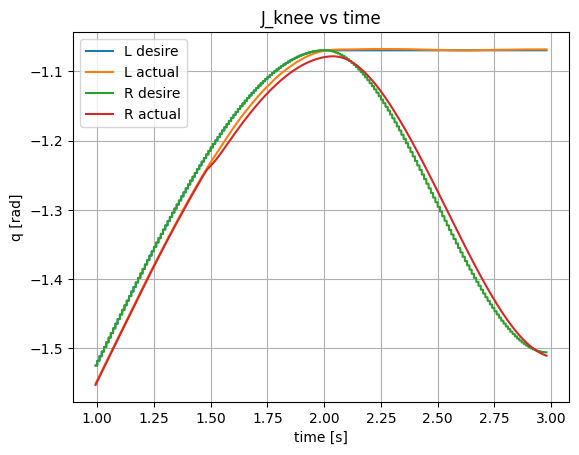

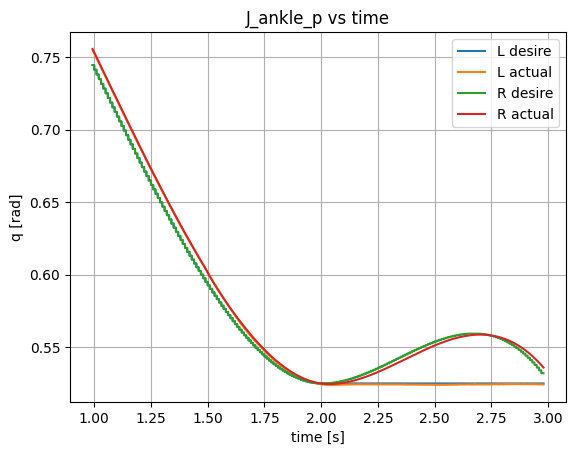

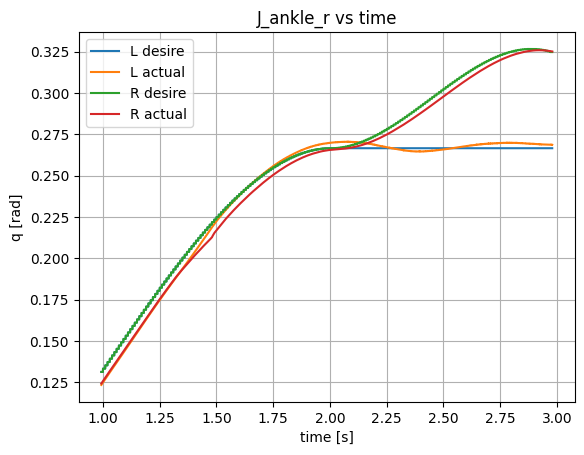

In [ ]:
start = 10 * 1000
end = 30 * 1000
for i in range(6):
    temp = name[i]
    sw_label = f"R_reference_{temp}"
    q_label = f"R_actual_{temp}"
    temp2 = np.ones(q_log.sample_times().size) * initial_joint_positions[0,6+i]
    plt.plot(q_log.sample_times()[start:end],L_log.data()[i,start:end],label = f"L desire")  
    # plt.plot(q_log.sample_times(),q_comp[i,:],label = f"1*gravity compensation")
    plt.plot(q_log.sample_times()[start:end],q_log.data()[i,start:end],label = f"L actual")
    # plt.plot(q_log.sample_times(),q_no_comp[i,:],label = f"no gravity compensation")
    plt.plot(q_log.sample_times()[start:end],R_log.data()[i,start:end],label = f"R desire")
    # plt.plot(q_log.sample_times(),q_comp[6+i,:],label = f"gravity compensation")
    plt.plot(q_log.sample_times()[start:end],q_log.data()[6+i,start:end],label = f"R actual")

    plt.xlabel("time [s]")
    plt.ylabel("q [rad]")
    plt.title(f"{temp} vs time")
    plt.legend()
    plt.grid()
    plt.show()

### qd vs time

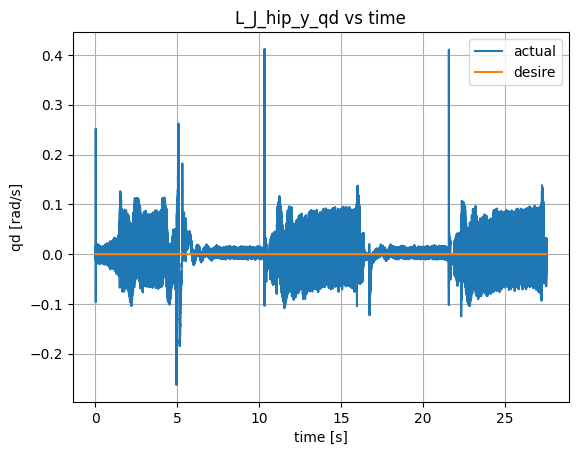

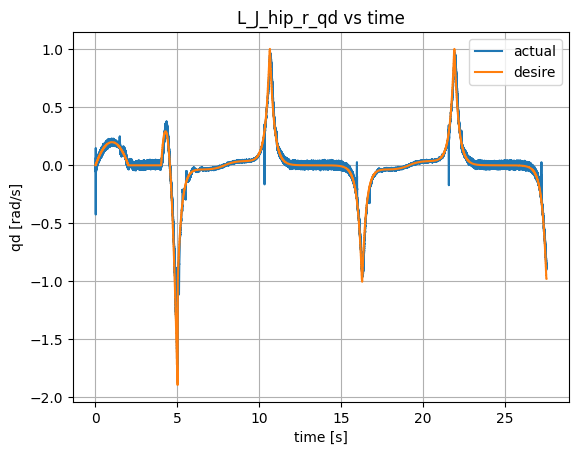

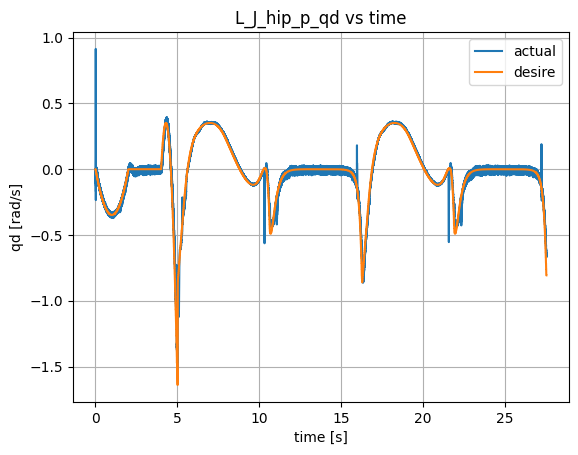

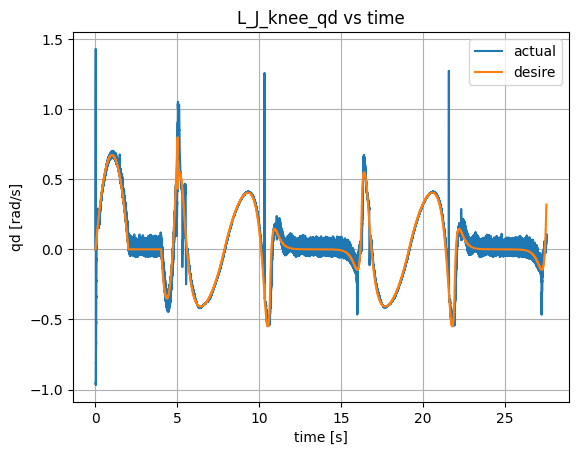

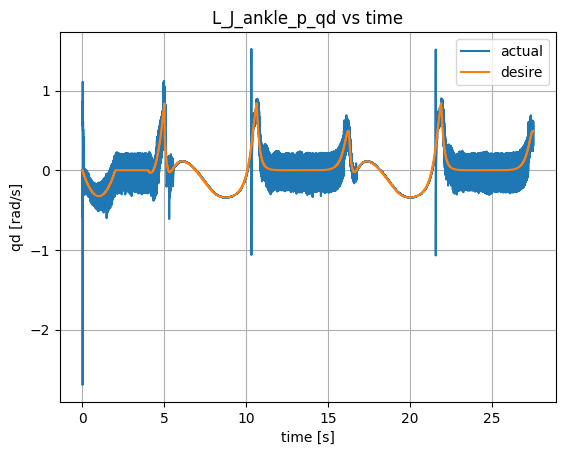

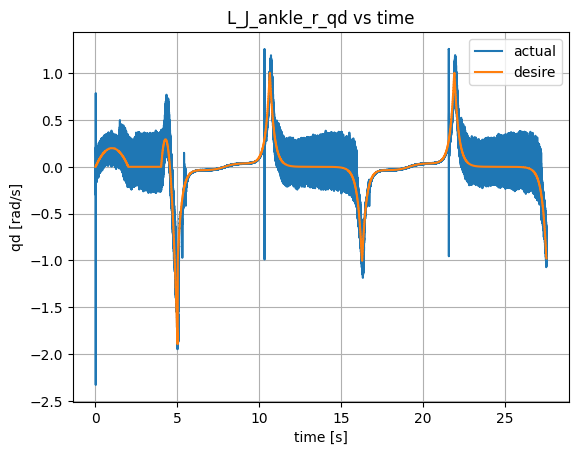

In [ ]:
for i in range(6):
    temp = name[i]
    sw_label = f"reference_qd_{temp}"
    qd_label = f"actual_qd_{temp}"
    # plt.plot(sw_qd_log.sample_times(),np.zeros(sw_qd_log.sample_times().size),label= "desire")
    plt.plot(L_qd_log.sample_times(),qd_log.data()[i,:],label= "actual")
    plt.plot(L_qd_log.sample_times(),L_qd_log.data()[i,:],label= "desire")

    plt.xlabel("time [s]")
    plt.ylabel("qd [rad/s]")
    plt.title(f"L_{temp}_qd vs time")
    plt.legend()
    plt.grid()
    plt.show()


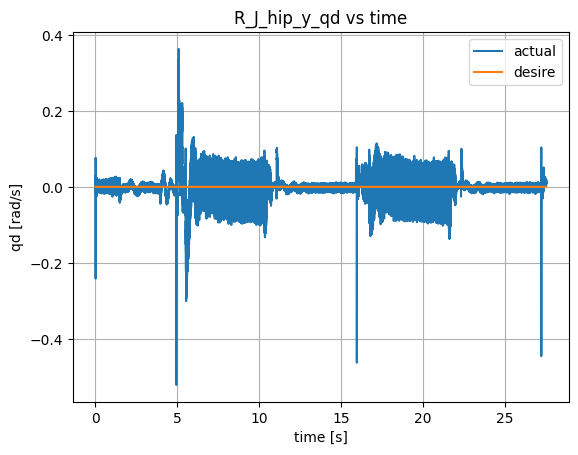

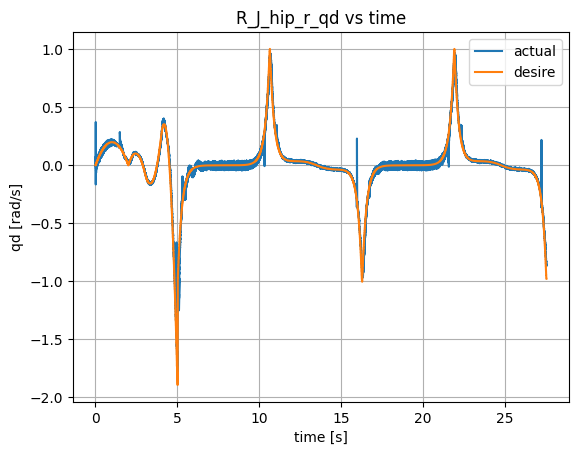

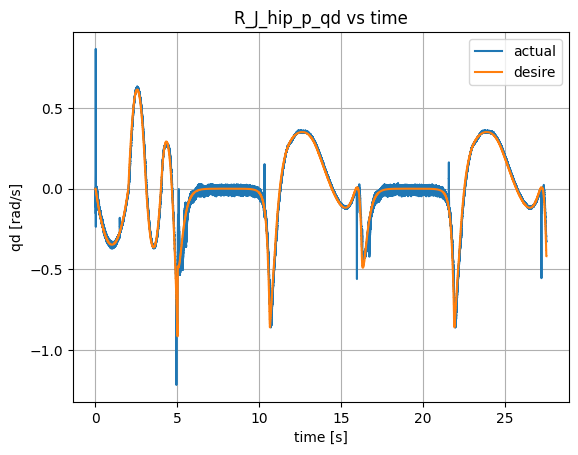

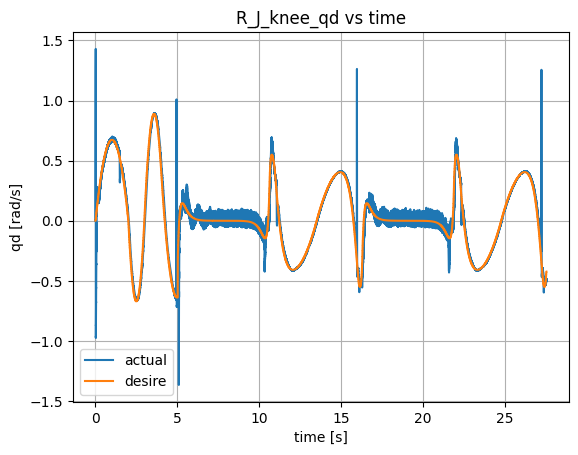

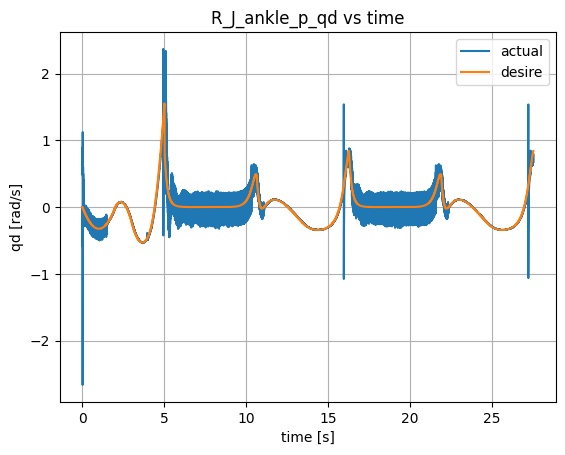

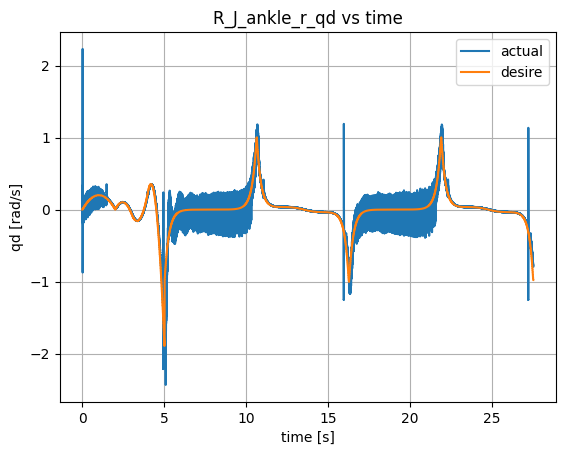

In [ ]:
# name = ["JL_hip_y","JL_hip_r","JL_hip_p","JL_knee","JL_ankle_p","JL_ankle_r"]
for i in range(6):
    temp = name[i]
    sw_label = f"reference_qd_{temp}"
    qd_label = f"actual_qd_{temp}"
    # plt.plot(sw_qd_log.sample_times(),np.zeros(sw_qd_log.sample_times().size),label= "desire")
    plt.plot(L_qd_log.sample_times(),qd_log.data()[i+6,:],label= "actual")
    plt.plot(L_qd_log.sample_times(),R_qd_log.data()[i,:],label= "desire")

    plt.xlabel("time [s]")
    plt.ylabel("qd [rad/s]")
    plt.title(f"R_{temp}_qd vs time")
    plt.legend()
    plt.grid()

    # if fixed_base:
    #     base = "fixed_base"
    # else:
    #     base = "floating_base"
    # if save_graph:
    #     # save_path = f"/home/tanawat/Documents/Thesis/Thesis_simulation/update_progress/{folder}/{sample_name}_{base}_{temp}_qd.png"  
    #     save_path = f"/home/tanawat/Documents/Thesis/Thesis_simulation/update_progress/plan_trajectory/{sample_name}_inittraj_{temp}_qd.png"
    # plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    

### torque vs time

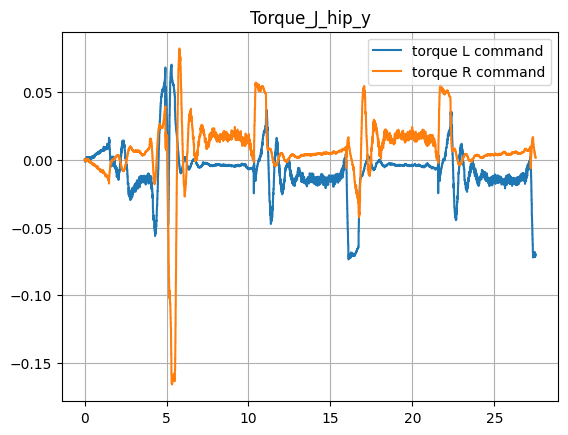

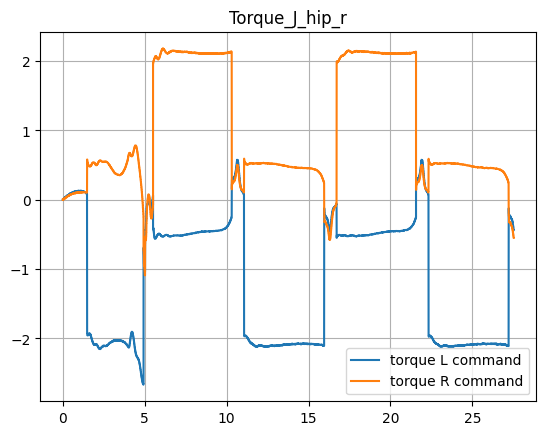

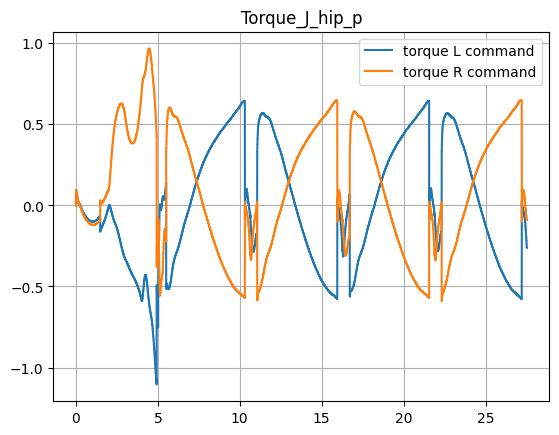

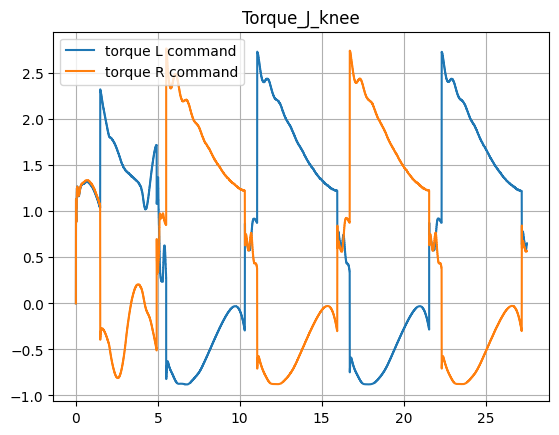

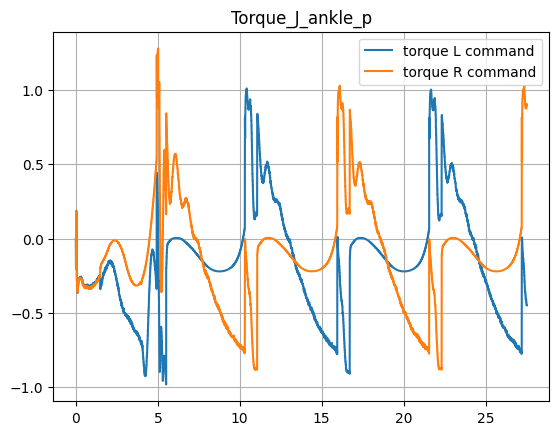

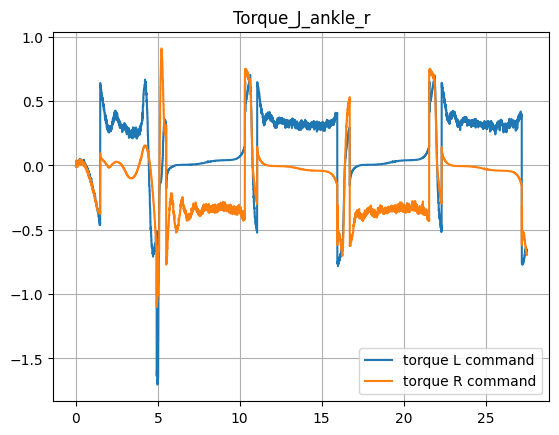

In [ ]:
for i in range(6):
    l = f"torque_id_{name[i]}"
    # plt.plot(t,torque_id_log.data()[6+i,:],label = "tau_g")
    plt.plot(t,torque_command_log.data()[i,:],label = "torque L command")
    plt.plot(t,torque_command_log.data()[i+6,:],label = "torque R command")

    plt.title(f"Torque_{name[i]}")
    plt.legend()
    plt.grid() 
    plt.show()

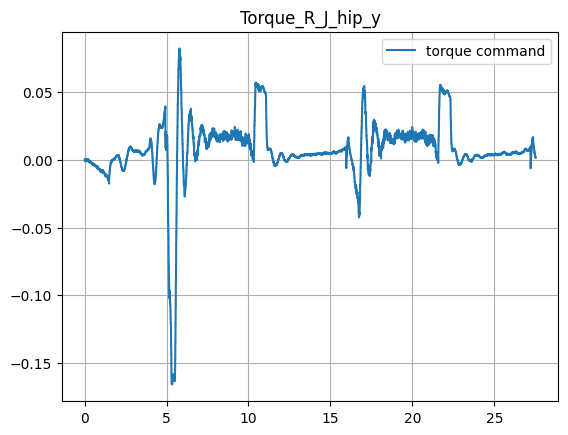

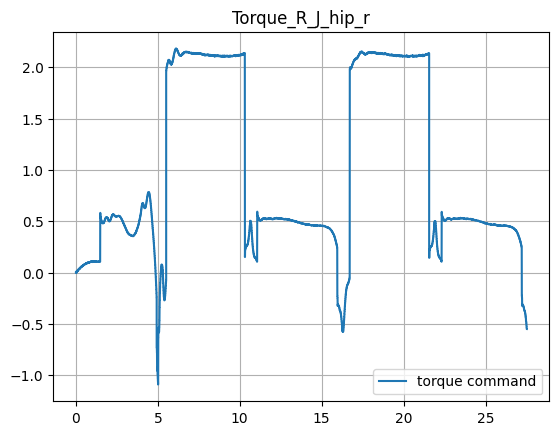

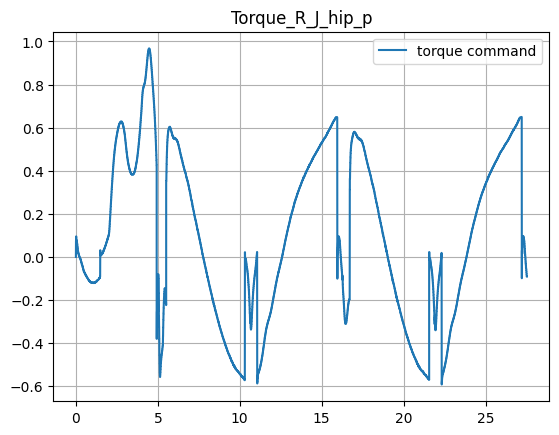

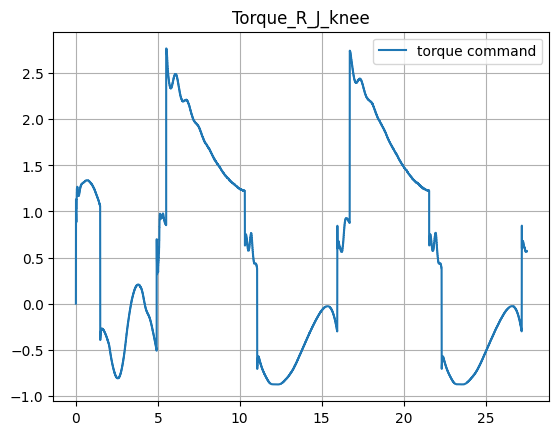

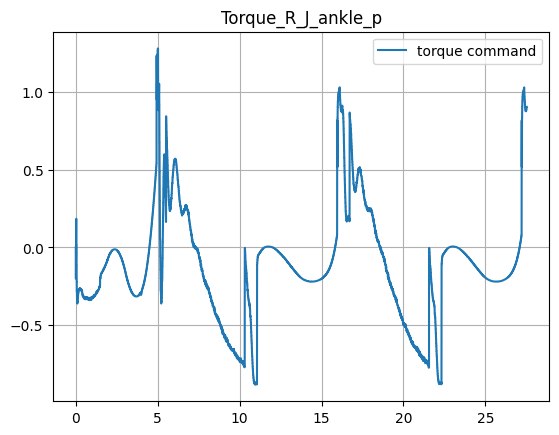

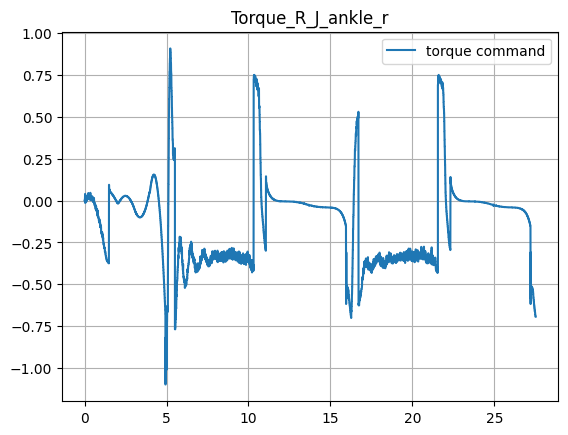

In [ ]:
for i in range(6):
    l = f"torque_id_{name[i]}"
    plt.plot(t,torque_command_log.data()[6+i,:],label = "torque command")


    plt.title(f"Torque_R_{name[i]}")
    plt.legend()
    plt.grid() 
    plt.show()

### CoM plot

In [ ]:
torso_P_com_log = com_base_logger.FindLog(context) 
W_P_torso_log = W_P_torso_logger.FindLog(context)
W_P_com_log = com_W_logger.FindLog(context)
t = q_log.sample_times()

In [ ]:
W_P_torso_log.data().shape

(3, 277013)

In [ ]:
W_P_com_x = W_P_com_log.data()[0,:]
W_P_com_y = W_P_com_log.data()[1,:]
W_P_com_z = W_P_com_log.data()[2,:]
W_P_torso_x = W_P_torso_log.data()[0,:]
W_P_torso_y = W_P_torso_log.data()[1,:]
W_P_torso_z = W_P_torso_log.data()[2,:]

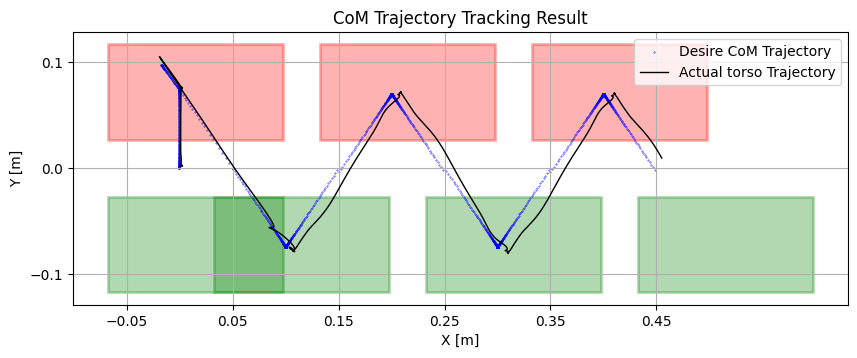

In [ ]:

DisplayGait2(x_data=CoM_x,
            y_data=CoM_y,
            x_data2=W_P_torso_x,
            y_data2=W_P_torso_y,
            rectangle_centers=foot_placement_position,
            rectangle_size=sole_size,
            des="torso")

In [ ]:

DisplayGait2(x_data=CoM_x,
            y_data=CoM_y,
            x_data2=W_P_com_x,
            y_data2=W_P_com_y,
            rectangle_centers=foot_placement_position,
            rectangle_size=sole_size,
            des="CoM")

KeyboardInterrupt: 

In [ ]:
def DisplayGait3(x_data, y_data,x_data2, y_data2,x_data3, y_data3, rectangle_centers, rectangle_size):
    # Create a figure and axis
    fig, ax = plt.subplots(figsize=(10, 8))
    # Add rectangles
    for center in rectangle_centers:
        rect_x = center[0] - rectangle_size[0] / 2  # Bottom-left corner x
        rect_y = center[1] - rectangle_size[1] / 2  # Bottom-left corner y
        edge_color = "green" if center[1] < 0 else "red"
        rectangle = patches.Rectangle(
            (rect_x+0.015, rect_y),
            rectangle_size[0],
            rectangle_size[1],
            edgecolor=edge_color,
            facecolor=edge_color,
            alpha=0.3, 
            linewidth=2,
        )
        ax.add_patch(rectangle)
    # Plot the trajectory
    ax.scatter(x_data, y_data, label="Desire CoM Trajectory", color="blue",s=0.1, linewidth=1)
    ax.plot(x_data2, y_data2, label="Actual CoM Trajectory", color="black", linewidth=1)
    ax.plot(x_data3, y_data3, label="Actual torso Trajectory", color="red", linewidth=1)
    # Set equal scaling for x and y axes
    ax.set_aspect("equal")

    # Set equal resolution by matching axis limits
    x_min, x_max = min(x_data) - 0.1, max(x_data) + 0.1
    y_min, y_max = min(y_data) - 0.1, max(y_data) + 0.1
    max_range = max(x_max - x_min, y_max - y_min)

    # Set tick steps to 0.1
    x_ticks = np.arange(-0.05, x_max, 0.1)
    y_ticks = np.arange(-0.1, 0.15, 0.1)
    ax.set_xticks(x_ticks)
    ax.set_yticks(y_ticks)

    # Set plot labels and legend
    ax.set_xlabel('X [m]')
    ax.set_ylabel('Y [m]')
    ax.set_title('CoM Trajectory Tracking Result')
    ax.legend()
    ax.grid(True)

    # Display the plot
    plt.show()

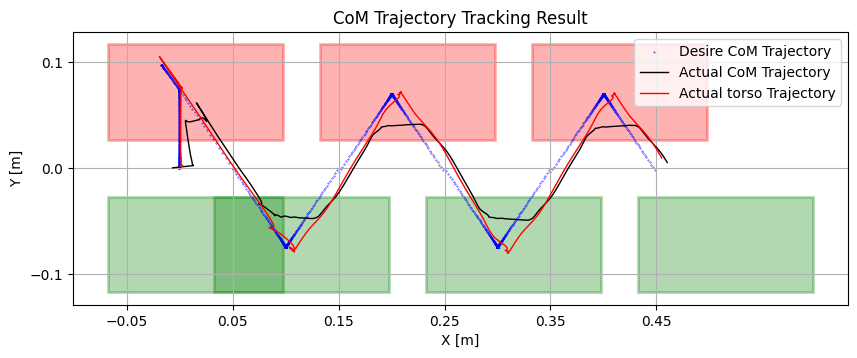

In [ ]:

DisplayGait3(x_data=CoM_x,
            y_data=CoM_y,
            x_data2=W_P_com_x,
            y_data2=W_P_com_y,
            x_data3=W_P_torso_x,
            y_data3=W_P_torso_y,
            rectangle_centers=foot_placement_position,
            rectangle_size=sole_size)